Error máximo, max(|thomas - solve_banded|) = 1.192e-07.

Pendiente log-log de |F_surf| para t >= 1e+05 s: -0.498.


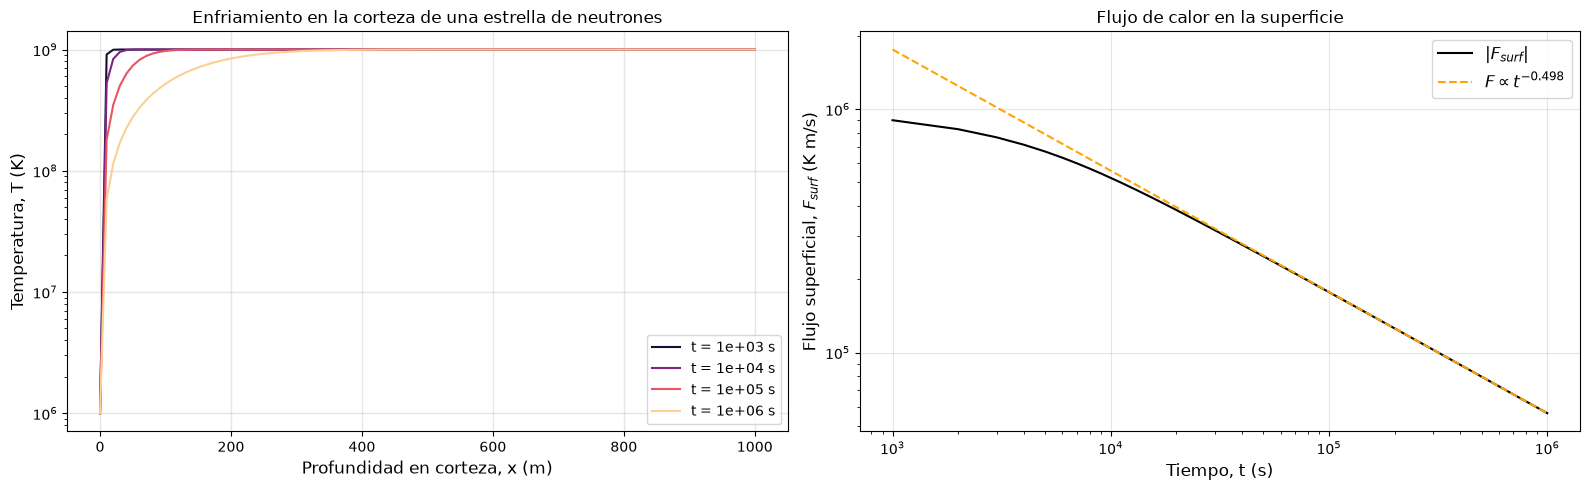

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import solve_banded
import matplotlib.cm as cm

# ------ CONSTANTES ------

L      = 1.0e3    # m, espesor corteza
alpha  = 1.0e-2   # m^2/s, difusividad
eps_nu = 1.0e-53  # K^-8 s^-1, emisión de neutrinos
T_core = 1.0e9    # K, condición x = L
T_surf = 1.0e6    # K, condición x = 0
t_max  = 1.e6     # s, duración simulación

# ------ PARÁMETROS ------
N   = 100
dx  = L / (N - 1)
dt  = 1.0e3
lam = alpha * dt / dx**2
n_steps = int(round(t_max / dt))

# if lam > 10.0:
#     raise ValueError('Lam muy grande, considerar reducir dt.')

# ------ CONDICIONES DE FRONTERA ------
x = np.linspace(0, L, N)         # Vector espacial
T = np.zeros(N)       # Matriz T (n_steps, N)
T[:] = T_core                  # Condición inicial uniforme
T[0], T[-1] = T_surf, T_core   # Superficie fría y núcleo caliente

# ------ CREACIÓN MATRIZ TRIDIAGONAL ------

# Sistema A T = b para el tiempo n+1 (El vector columna T^{n+1} es la incógnita)
def construct_matrix(T, lam, eps_nu, dt, N):
    b = np.zeros(N)

    diag_inf = np.zeros(N)
    diag_pri = np.zeros(N)
    diag_sup = np.zeros(N)

    diag_sup[1:N-1] = -lam / 2
    diag_pri[1:N-1] = 1 + lam
    diag_inf[1:N-1] = -lam / 2

    Q_nu = eps_nu * T[1:N-1]**5        
    b[1:N-1] = (lam/2)*T[0:N-2] + (1 - lam)*T[1:N-1] + (lam/2)*T[2:N] - dt*Q_nu


    # Condiciones de frontera:
    b[1]  = b[1]  + (lam / 2) * T[0]
    b[-2] = b[-2] + (lam / 2) * T[-1] 

    return diag_inf, diag_pri, diag_sup, b

# ------ ALGORITMO DE THOMAS ------

def thomas(a, b, c, d, N):
    # a == diag_inf 
    # b == diag_pri
    # c == diag_sup
    # d == vector rhs
    c_prime = np.zeros(N)
    d_prime = np.zeros(N)
    x = np.zeros(N)

    c_prime[1] = c[1] / b[1]
    d_prime[1] = d[1] / b[1]

    for i in range(2, N-1):
        m = b[i] - a[i] * c_prime[i-1]
        c_prime[i] = c[i] / m
        d_prime[i] = (d[i] - a[i] * d_prime[i-1]) / m
    # Sustitución hacia atrás:
    x[N-2] = d_prime[N-2]
    for i in range(N-3, 0, -1):
        x[i] = d_prime[i] - c_prime[i] * x[i+1]
    
    return x

# ------ VERIFICACIÓN CON SOLVE_BANDED ------

a, b, c, rhs = construct_matrix(T, lam, eps_nu, dt, N)
ab = np.zeros((3, N-2))
ab[0,1:] = c[2:N-1]
ab[1] = b[1:N-1]
ab[2,:-1] = a[2:N-1]
ver = solve_banded((1,1), ab, rhs[1:N-1])
num = thomas(a, b, c, rhs, N)[1:N-1]
print(f'Error máximo, max(|thomas - solve_banded|) = {np.max(np.abs(ver - num)):.3e}.')


# ------ INTEGRACIÓN TEMPORAL ------
tiempos_salida = [1e3, 1e4, 1e5, 1e6] # secs
history = []
F_arr, t_arr = [], []
t = 0.0

for i in range(1, n_steps + 1):
    a, b, c, rhs = construct_matrix(T, lam, eps_nu, dt, N)
    # Resolver con Thomas
    T_interior = thomas(a, b, c, rhs, N)
    # Actualizar temp
    T = T_interior
    T[0] = T_surf
    T[N-1] = T_core
    t += dt
    # Diagnóstico:
    F_surf = -alpha * (T[1] - T[0])/dx
    # Guardar:
    F_arr.append(F_surf)
    t_arr.append(t)
    if t in tiempos_salida:
        history.append([T.copy(), t])

t_arr, F_arr = np.array(t_arr), np.array(F_arr)
# Tiempos grandes para ley de potencias del flujo
tol = 1e5
mask = t_arr >= 1e5
slope, intercept = np.polyfit(np.log10(t_arr[mask]), np.log10(np.abs(F_arr[mask])), 1)
print(f'\nPendiente log-log de |F_surf| para t >= {tol:.0e} s: {slope:.3f}.')

# Graficas:
colors = cm.magma(np.linspace(0.1, 0.9, 4))


fig, (ax1,ax2) = plt.subplots(1, 2, figsize=(16, 5))
for i, (T_snap, t_snap) in enumerate(history):
    color=colors[i]
    ax1.semilogy(x, T_snap, color=color, label=f't = {t_snap:.0e} s')


ax1.grid(alpha=0.2, color='gray', lw=1)
ax1.set_xlabel('Profundidad en corteza, x (m)', fontsize=12); ax1.set_ylabel('Temperatura, T (K)', fontsize=12); ax1.set_title('Enfriamiento en la corteza de una estrella de neutrones')
ax1.legend()

ax2.loglog(t_arr, np.abs(F_arr), color='k', label=r'$|F_{surf}|$') 
ax2.loglog(t_arr, 10**intercept * t_arr**slope, ls='--', color='orange', label=rf'$F \propto t^{{{slope:.3f}}}$')
ax2.grid(alpha=0.2, color='gray')
ax2.set_xlabel('Tiempo, t (s)', fontsize=12); ax2.set_ylabel(r'Flujo superficial, $F_{surf}$ (K m/s)', fontsize=12); ax2.set_title('Flujo de calor en la superficie')
ax2.legend(fontsize=12)
plt.tight_layout()
plt.show()

Los tres métodos nacen de tomar pesos distintos en la evaluación temporal de la segunda derivada de $T$ respecto a $x$. En el método explícito, se calcula en el tiempo presente $n$, en el método implícito se calcula en el tiempo siguiente $n+1$, mientras que en el método de Crank-Nicolson se calcula como un promedio de ambos tiempos. Esto se puede reproducir con el parámetro $\theta$, que representa el peso de cada evaluación:

\begin{align*}
    \frac{T_i ^{n+1} - T_i ^{n}}{\Delta t} &= \alpha \left[ \theta \frac{T_{i+1} ^{n+1} - 2T_i ^{n+1} + T_{i-1}^{n+1}}{(\Delta x)^2} + (1 - \theta) \frac{T_{i+1} ^n - 2T_i ^n + T_{i-1}^n}{(\Delta x)^2} \right] - Q_{\nu}
\end{align*}

El término de $\theta$ acompaña a la segunda derivada evaluada en el tiempo siguiente, mientras que el término $(1-\theta)$ acompaña la segunda derivada en el tiempo presente. Así, para $\theta = 0$ se recupera el método **explícito**, para $\theta = 1$ el método **implícito**, y para $\theta = 1/2$ el método **Crank-Nicolson**.

Para comparar los tres métodos, se reformula el procedimiento anterior:

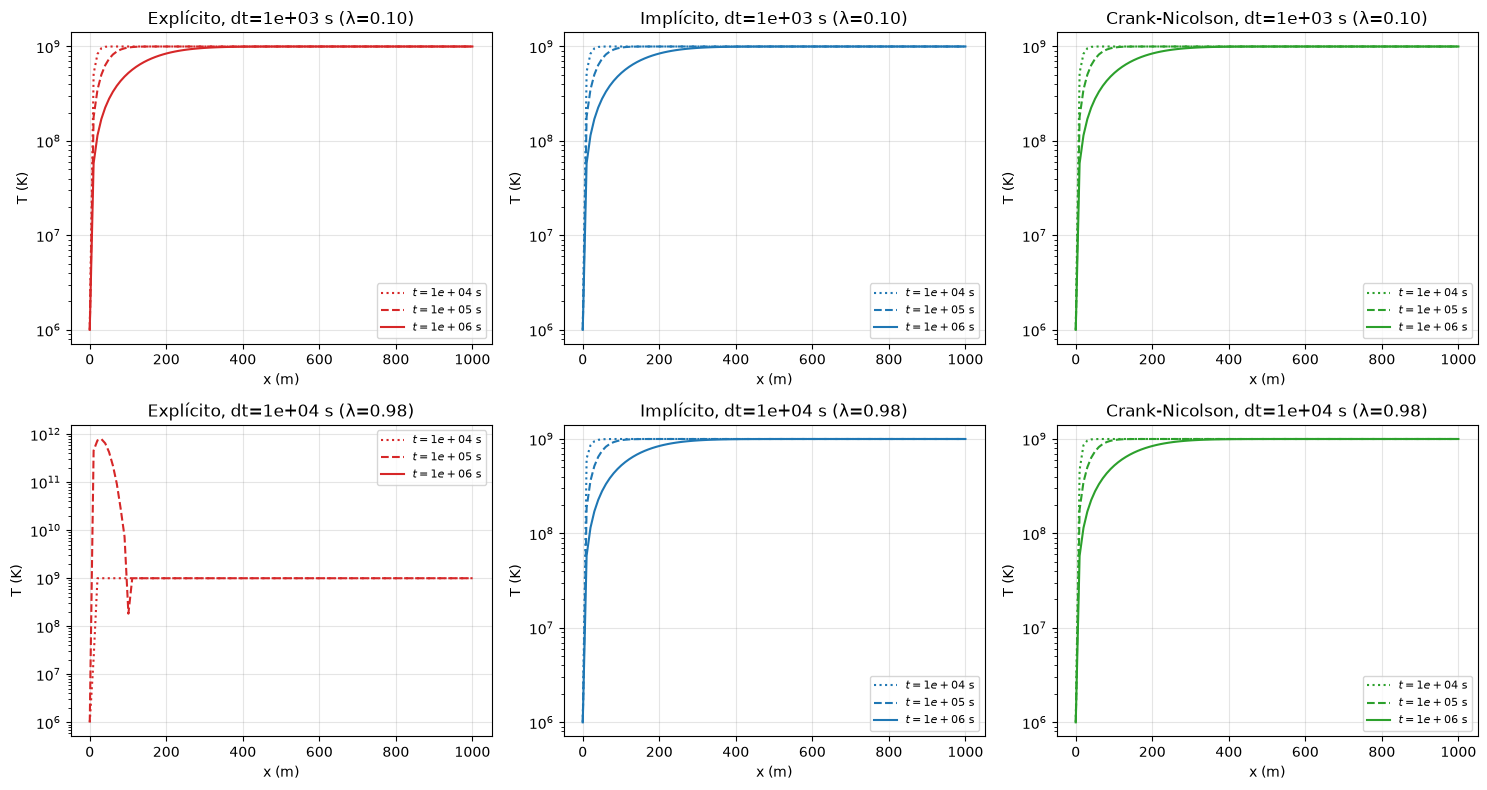

In [13]:
tiempos_salida = [1e4, 1e5, 1e6]

def simulation_T(dt, theta):
    # Definición de parámetros y diagonales según theta
    lam = alpha * dt / dx**2
    n_steps = int(round(t_max/dt))
    T = np.full(N, T_core)
    T[0], T[-1] = T_surf, T_core
    a = np.full(N, -theta*lam) 
    b = np.full(N, 1 + 2*theta*lam)
    c = np.full(N, -theta*lam)
    rhs = np.zeros(N)
    # Diccionario para guardar resultados
    sol = {}
    with np.errstate(all='ignore'):
        for n in range(1, n_steps + 1):
            Q_nu = eps_nu * T[1:-1]**5  
            rhs[1:-1] = T[1:-1] + (1 - theta) * lam * (T[:-2] - 2*T[1:-1] + T[2:]) - dt*Q_nu

            rhs[1]  = rhs[1]  + theta * lam * T_surf
            rhs[-2] = rhs[-2] + theta * lam * T_core

            # Método explícito:
            if theta == 0:
                T = rhs
            # El resto de métodos:
            else:
                T = thomas(a, b, c, rhs, N)

            T[0], T[-1] = T_surf, T_core
            t = n*dt
            if t in tiempos_salida:
                sol[t] = T.copy()

    return lam, sol

# (Método, theta)
metodos = [('Explícito', 0.0), ('Implícito', 1.0), ('Crank-Nicolson', 0.5)]
# Pasos temporales para observar estabilidad
dts = [1e3, 1e4]
# Guardar resultados:
resultados = {}

# for dt in dts:
#     for nombre, theta in metodos:
#         lam, sol = simulation_T(dt, theta)
#         resultados[(dt, nombre)] = (lam, sol)

fig, ax = plt.subplots(2, 3, figsize=(15, 8))
cols = {"Explícito":"tab:red", "Implícito":"tab:blue", "Crank-Nicolson":"tab:green"}

for i, dt in enumerate(dts):
    for j, (nombre, theta) in enumerate(metodos):
        lam, sol = simulation_T(dt, theta)
        for (t, ls) in [(1e4, ':'), (1e5, '--'), (1e6, '-')]:
            T = sol[t]
            ax[i, j].semilogy(x, np.abs(T) if np.all(np.isfinite(T)) else np.full(N, np.nan), ls, color=cols[nombre], label=f'$t={t:.0e}$ s')

        ax[i, j].set_title(f"{nombre}, dt={dt:.0e} s (λ={lam:.2f})")
        ax[i, j].set_xlabel("x (m)"); ax[i, j].set_ylabel("T (K)")
        ax[i, j].grid(alpha=0.2, color='gray')
        ax[i, j].legend(fontsize=8)

plt.tight_layout()
plt.show()

Es posible observar que para $\Delta t = 10^4 s$, el método explícito se vuelve inestable, siendo que se notan oscilaciones no físicas en el tiempo $t = 10^5s$, y para el tiempo final de $t = 10^6 s$ no se grafica una curva debido a que se incumple con el condicional ```np.all(np.isfinite(T))```, mostrando que en este punto se encuentran valores no finitos. Esto es en concordancia con lo esperado, pues la estabilidad del método explícito se mantiene para valores de $\lambda \leq 1/2$, y para $\Delta t = 10^4 s$, se tiene un $\lambda$ de $0.98$, sobrepasando este límite. Por otro lado, los métodos implícito y Crank-Nicolson se mantienen estables independientemente del valor de $\Delta t$.